
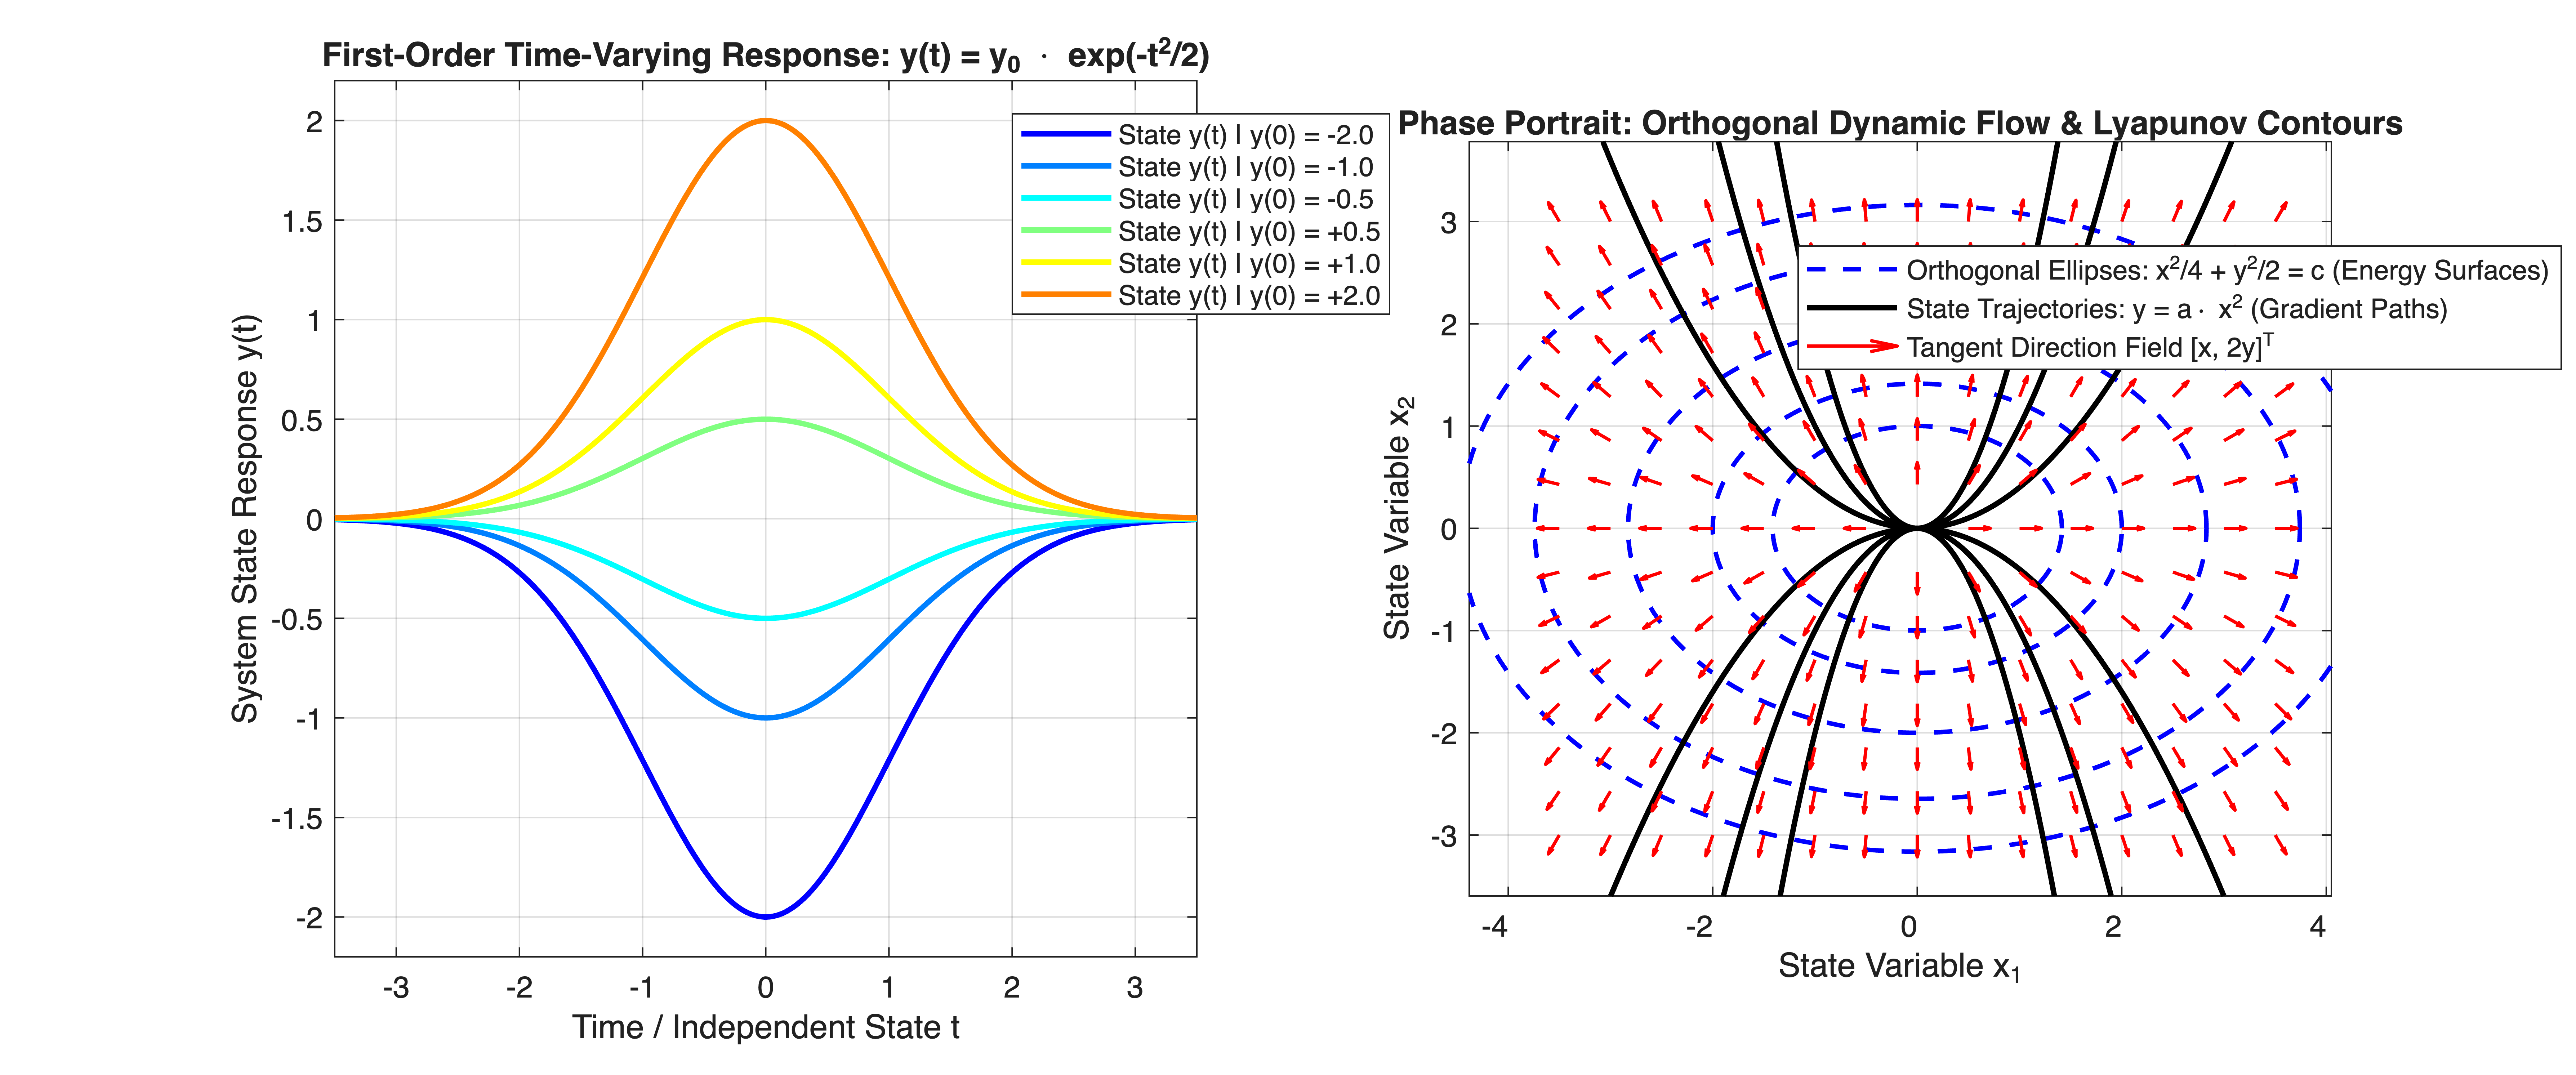

In [1]:
%% MIT 18.01 Lecture 16: ODE Separation of Variables & Phase Portrait
% MBD Concept Mapping: First-order ordinary differential equations represent
% continuous plant state equations. The orthogonal trajectories illustrate the
% geometric duality between system state trajectories (gradient flow lines)
% and Lyapunov equipotential energy level sets (surfaces of constant value).


clear; clc; close all;


%% Part 1: State Evolution of System dy/dt + t*y = 0 with Multiple Initial Conditions
% Analytic solution from Lecture 16: y(t) = y0 * exp(-t^2 / 2)
t_span = linspace(-3.5, 3.5, 300);
y0_conditions = [-2.0, -1.0, -0.5, 0.5, 1.0, 2.0];


figure('Color', 'w', 'Position', [100, 100, 1200, 500]);


subplot(1, 2, 1);
colors = jet(length(y0_conditions));
for k = 1:length(y0_conditions)
    y0_val = y0_conditions(k);
    y_response = y0_val * exp(-0.5 * (t_span.^2));
    plot(t_span, y_response, 'LineWidth', 1.8, 'Color', colors(k, :), ...
        'DisplayName', sprintf('State y(t) | y(0) = %+.1f', y0_val)); hold on;
end


grid on;
xlabel('Time / Independent State t');
ylabel('System State Response y(t)');
title('First-Order Time-Varying Response: y(t) = y_0 \cdot exp(-t^2/2)');
legend('Location', 'northeast');
xlim([-3.5, 3.5]); ylim([-2.2, 2.2]);


%% Part 2: Phase Portrait: Dynamic Trajectories vs. Orthogonal Energy Surfaces
% Lecture 16 Example 3: Parabolas y = a * x^2 (State Flow Trajectories)
% Lecture 16 Example 4: Ellipses x^2/4 + y^2/2 = c (Orthogonal Level Sets)
subplot(1, 2, 2);


% 1. Plot Family of Orthogonal Ellipses (Lyapunov equipotential surfaces)
c_levels = [0.5, 1.0, 2.0, 3.5, 5.0];
theta_grid = linspace(0, 2*pi, 300);
for i = 1:length(c_levels)
    c_val = c_levels(i);
    a_axis = 2 * sqrt(c_val);       % Semi-major axis in x
    b_axis = sqrt(2 * c_val);       % Semi-minor axis in y (ratio = sqrt(2))
    x_ellipse = a_axis * cos(theta_grid);
    y_ellipse = b_axis * sin(theta_grid);


    if i == 1
        plot(x_ellipse, y_ellipse, 'b--', 'LineWidth', 1.5, ...
            'DisplayName', 'Orthogonal Ellipses: x^2/4 + y^2/2 = c (Energy Surfaces)'); hold on;
    else
        plot(x_ellipse, y_ellipse, 'b--', 'LineWidth', 1.5, 'HandleVisibility', 'off');
    end
end


% 2. Plot Family of Parabolas (System dynamic phase trajectories)
a_params = [-2.0, -1.0, -0.4, 0.4, 1.0, 2.0];
x_parabola = linspace(-4, 4, 300);
for j = 1:length(a_params)
    a_val = a_params(j);
    y_parab = a_val * (x_parabola.^2);


    if j == 1
        plot(x_parabola, y_parab, 'k-', 'LineWidth', 1.8, ...
            'DisplayName', 'State Trajectories: y = a\cdot x^2 (Gradient Paths)');
    else
        plot(x_parabola, y_parab, 'k-', 'LineWidth', 1.8, 'HandleVisibility', 'off');
    end
end


% 3. Overlay Vector Field Quiver to highlight orthogonal intersection
[X_mesh, Y_mesh] = meshgrid(linspace(-3.5, 3.5, 15), linspace(-3.0, 3.0, 15));
% Slope of parabola is dy/dx = 2*y/x => vector [dx, dy] = [x, 2*y]
DX = X_mesh;
DY = 2 * Y_mesh;
norm_factor = sqrt(DX.^2 + DY.^2) + 1e-6;
quiver(X_mesh, Y_mesh, DX./norm_factor, DY./norm_factor, 0.35, 'r', ...
    'LineWidth', 1.1, 'DisplayName', 'Tangent Direction Field [x, 2y]^T');


grid on; axis equal;
xlim([-4, 4]); ylim([-3.5, 3.5]);
xlabel('State Variable x_1');
ylabel('State Variable x_2');
title('Phase Portrait: Orthogonal Dynamic Flow & Lyapunov Contours');
legend('Location', 'northeast');